# Analisis Eksperimen Prompting LLM untuk Deteksi Kerentanan Java

Notebook ini menganalisis 16 berkas ringkasan eksperimen: **DeepSeek Coder 6.7B** dan **Gemma4 E4B (thinking aktif)**, masing-masing dengan 8 kombinasi strategi prompting dan input (kode saja vs kode + FindSecBugs).

## Tujuan analisis
1. Memeriksa kelengkapan dan validitas keluaran setiap skenario.
2. Membandingkan proporsi prediksi rentan, jumlah keluaran valid, respons tidak valid, dan waktu inferensi.
3. Menganalisis distribusi CWE yang diprediksi.
4. Memvisualisasikan hasil **secara terpisah untuk tiap model** agar grafik tidak terlalu panjang.
5. Menghitung metrik deteksi dan klasifikasi terhadap ground truth **hanya jika berkas label ground truth tersedia**.

> **Batasan penting:** berkas `.summary.json` yang diberikan berisi prediksi model dan statistik parsing, tetapi tidak memuat label ground truth per sampel. Karena itu, notebook ini tidak menyebut jumlah prediksi rentan sebagai true positive dan tidak menghitung accuracy, precision, recall, F1, atau false-positive rate tanpa ground truth. Prediksi rentan bukan berarti benar-benar rentan.

## 1. Persiapan dan pemuatan data

Letakkan seluruh berkas `*.summary.json` di folder yang sama dengan notebook. Notebook akan membaca semua berkas ringkasan yang ditemukan.

In [6]:
from pathlib import Path
import json, re, math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Notebook execution normally uses the notebook directory as the working directory.
# These fallbacks also make the file runnable from the repository root or VS Code.
data_candidates = [Path.cwd(), Path.cwd() / "results" / "llm" / "raw", Path("results/llm/raw")]
DATA_DIR = next((folder for folder in data_candidates if folder.exists() and list(folder.glob("*.summary.json"))), None)
if DATA_DIR is None:
    raise FileNotFoundError("Tidak ditemukan berkas *.summary.json pada direktori notebook atau direktori hasil LLM.")
DATA_DIR = DATA_DIR.resolve()
SUMMARY_FILES = sorted(DATA_DIR.glob("*.summary.json"))

strategy_order = ["zero-shot", "cot", "tot", "baseline-1", "baseline-2"]
strategy_names = {
    "zero-shot-none": "zero-shot", "zero-shot-findsecbugs": "zero-shot",
    "cot-none": "cot", "cot-findsecbugs": "cot",
    "tot-none": "tot", "tot-findsecbugs": "tot",
}

def normalize_strategy(value):
    value = str(value).strip().lower()
    if value in strategy_names:
        return strategy_names[value]
    value = re.sub(r"-(?:none|findsecbugs)$", "", value)
    return value if value in strategy_order else value

records = []
predictions_by_scenario = {}
for path in SUMMARY_FILES:
    with path.open(encoding="utf-8") as f:
        d = json.load(f)

    model_raw = str(d.get("model", path.name.split("__")[0]))
    model = "DeepSeek Coder 6.7B" if "deepseek" in model_raw.lower() else (
        "Gemma4 E4B (thinking aktif)" if "gemma" in model_raw.lower() else model_raw
    )
    scenario = normalize_strategy(d.get("scenario_id", "unknown"))
    sast_raw = d.get("sast", "unknown")
    sast = "Code + FindSecBugs" if sast_raw == "findsecbugs" else (
        "Code only" if sast_raw == "none" else str(sast_raw)
    )
    valid = int(d.get("predictions_valid", 0))
    total = int(d.get("dataset_records", 0))
    invalid = int(d.get("invalid_responses", max(total-valid, 0)))
    elapsed = float(d.get("elapsed_seconds", np.nan))
    preds = d.get("predictions", []) or []
    key = (model, scenario, sast)
    predictions_by_scenario[key] = preds

    vulnerable = int(d.get("vulnerable_detected_by_model", 0))
    records.append({
        "file": path.name, "model": model, "scenario": scenario, "sast": sast,
        "dataset_records": total, "predictions_valid": valid,
        "invalid_responses": invalid, "failed_calls": int(d.get("failed_calls", 0)),
        "missing_predictions": int(d.get("missing_predictions", 0)),
        "predicted_vulnerable": vulnerable,
        "predicted_not_vulnerable": int(d.get("classified_not_vulnerable_by_model", 0)),
        "vulnerable_with_cwe": int(d.get("vulnerable_predictions_with_cwe", 0)),
        "elapsed_seconds": elapsed,
        "elapsed_hours": elapsed/3600 if not np.isnan(elapsed) else np.nan,
        "valid_rate_pct": 100*valid/total if total else np.nan,
        "invalid_rate_pct": 100*invalid/total if total else np.nan,
        "predicted_vulnerable_pct_of_valid": 100*vulnerable/valid if valid else np.nan,
        "generated_at_utc": d.get("generated_at_utc"), "dataset_sha256": d.get("dataset_sha256"),
        "predictions_list_length": len(preds),
    })

summary = pd.DataFrame(records)
summary["scenario"] = pd.Categorical(summary["scenario"].astype("string"), categories=strategy_order, ordered=True)
summary["scenario_label"] = summary["scenario"].astype("string").fillna("unknown")
summary = summary.sort_values(["model", "sast", "scenario"]).reset_index(drop=True)
print(f"Direktori data: {DATA_DIR}")
print(f"Jumlah berkas ringkasan: {len(summary)}")
print(f"Jumlah sampel target: {sorted(summary['dataset_records'].dropna().unique().tolist())}")
display(summary[["model","scenario_label","sast","dataset_records","predictions_valid","invalid_responses",
                 "valid_rate_pct","predicted_vulnerable","predicted_not_vulnerable",
                 "elapsed_hours","failed_calls","dataset_sha256"]].round(2))


Direktori data: /home/nasyikhqusyairy/Projects/repositories/sast-llm-benchmark/results/llm/raw
Jumlah berkas ringkasan: 16
Jumlah sampel target: [2740]


,model,scenario_label,sast,dataset_records,predictions_valid,invalid_responses,valid_rate_pct,predicted_vulnerable,predicted_not_vulnerable,elapsed_hours,failed_calls,dataset_sha256
0,DeepSeek Coder 6.7B,zero-shot,Code + FindSecBugs,2740,2651,89,96.75,2556,95,3.60,0,dc4dbfe4f54772afe441369580278780f6de1fcd306f18...
1,DeepSeek Coder 6.7B,cot,Code + FindSecBugs,2740,2646,94,96.57,2550,96,4.37,0,dc4dbfe4f54772afe441369580278780f6de1fcd306f18...
2,DeepSeek Coder 6.7B,tot,Code + FindSecBugs,2740,2650,90,96.72,2565,85,3.99,0,dc4dbfe4f54772afe441369580278780f6de1fcd306f18...
3,DeepSeek Coder 6.7B,baseline-2,Code + FindSecBugs,2740,2714,26,99.05,2613,101,2.95,0,dc4dbfe4f54772afe441369580278780f6de1fcd306f18...
4,DeepSeek Coder 6.7B,zero-shot,Code only,2740,2739,1,99.96,1570,1169,3.20,0,dc4dbfe4f54772afe441369580278780f6de1fcd306f18...
5,DeepSeek Coder 6.7B,cot,Code only,2740,2734,6,99.78,857,1877,2.67,0,dc4dbfe4f54772afe441369580278780f6de1fcd306f18...
6,DeepSeek Coder 6.7B,tot,Code only,2740,2705,30,98.72,1743,962,4.35,5,dc4dbfe4f54772afe441369580278780f6de1fcd306f18...
7,DeepSeek Coder 6.7B,baseline-1,Code only,2740,2537,203,92.59,1377,1160,2.74,0,dc4dbfe4f54772afe441369580278780f6de1fcd306f18...
8,Gemma4 E4B (thinking aktif),zero-shot,Code + FindSecBugs,2740,2599,141,94.85,1916,683,5.70,0,dc4dbfe4f54772afe441369580278780f6de1fcd306f18...
9,Gemma4 E4B (thinking aktif),cot,Code + FindSecBugs,2740,2354,386,85.91,1702,652,6.89,0,dc4dbfe4f54772afe441369580278780f6de1fcd306f18...


## 2. Pemeriksaan konsistensi eksperimen

Bagian ini memeriksa apakah semua skenario menggunakan hash dataset yang sama, apakah jumlah sampel konsisten, dan apakah keluaran valid ditambah respons tidak valid sesuai dengan ukuran dataset. Ketidaksesuaian ditampilkan untuk ditinjau, bukan diperbaiki diam-diam.

In [7]:
print("Hash dataset:")
display(summary.groupby("model")["dataset_sha256"].nunique().rename("jumlah_hash_unik").to_frame())

print("Jumlah record dataset per model:")
display(summary.groupby("model")["dataset_records"].agg(["min","max","nunique"]))

summary["valid_plus_invalid"] = summary["predictions_valid"] + summary["invalid_responses"]
summary["count_gap"] = summary["dataset_records"] - summary["valid_plus_invalid"]
summary["prediction_list_gap"] = summary["predictions_valid"] - summary["predictions_list_length"]

display(summary[["model","scenario","sast","dataset_records","predictions_valid",
                 "invalid_responses","valid_plus_invalid","count_gap",
                 "predictions_list_length","prediction_list_gap","missing_predictions",
                 "failed_calls"]])


Hash dataset:


,jumlah_hash_unik
model,
DeepSeek Coder 6.7B,1
Gemma4 E4B (thinking aktif),1


Jumlah record dataset per model:


,min,max,nunique
model,,,
DeepSeek Coder 6.7B,2740,2740,1
Gemma4 E4B (thinking aktif),2740,2740,1


,model,scenario,sast,dataset_records,predictions_valid,invalid_responses,valid_plus_invalid,count_gap,predictions_list_length,prediction_list_gap,missing_predictions,failed_calls
0,DeepSeek Coder 6.7B,zero-shot,Code + FindSecBugs,2740,2651,89,2740,0,2651,0,0,0
1,DeepSeek Coder 6.7B,cot,Code + FindSecBugs,2740,2646,94,2740,0,2646,0,0,0
2,DeepSeek Coder 6.7B,tot,Code + FindSecBugs,2740,2650,90,2740,0,2650,0,0,0
3,DeepSeek Coder 6.7B,baseline-2,Code + FindSecBugs,2740,2714,26,2740,0,2714,0,0,0
4,DeepSeek Coder 6.7B,zero-shot,Code only,2740,2739,1,2740,0,2739,0,0,0
5,DeepSeek Coder 6.7B,cot,Code only,2740,2734,6,2740,0,2734,0,0,0
6,DeepSeek Coder 6.7B,tot,Code only,2740,2705,30,2735,5,2705,0,0,5
7,DeepSeek Coder 6.7B,baseline-1,Code only,2740,2537,203,2740,0,2537,0,0,0
8,Gemma4 E4B (thinking aktif),zero-shot,Code + FindSecBugs,2740,2599,141,2740,0,2599,0,0,0
9,Gemma4 E4B (thinking aktif),cot,Code + FindSecBugs,2740,2354,386,2740,0,2354,0,0,0


## 3. Ringkasan lintas skenario

Tabel ini bersifat deskriptif. Kolom `predicted_vulnerable` menunjukkan berapa banyak keluaran valid yang menyatakan sampel rentan, **bukan** berapa banyak kerentanan yang berhasil dideteksi dengan benar.

In [8]:
overview = summary[[
    "model","scenario","sast","predictions_valid","valid_rate_pct",
    "predicted_vulnerable","predicted_not_vulnerable",
    "predicted_vulnerable_pct_of_valid","invalid_responses",
    "invalid_rate_pct","elapsed_hours"
]].copy()
display(overview.round(2))


,model,scenario,sast,predictions_valid,valid_rate_pct,predicted_vulnerable,predicted_not_vulnerable,predicted_vulnerable_pct_of_valid,invalid_responses,invalid_rate_pct,elapsed_hours
0,DeepSeek Coder 6.7B,zero-shot,Code + FindSecBugs,2651,96.75,2556,95,96.42,89,3.25,3.60
1,DeepSeek Coder 6.7B,cot,Code + FindSecBugs,2646,96.57,2550,96,96.37,94,3.43,4.37
2,DeepSeek Coder 6.7B,tot,Code + FindSecBugs,2650,96.72,2565,85,96.79,90,3.28,3.99
3,DeepSeek Coder 6.7B,baseline-2,Code + FindSecBugs,2714,99.05,2613,101,96.28,26,0.95,2.95
4,DeepSeek Coder 6.7B,zero-shot,Code only,2739,99.96,1570,1169,57.32,1,0.04,3.20
5,DeepSeek Coder 6.7B,cot,Code only,2734,99.78,857,1877,31.35,6,0.22,2.67
6,DeepSeek Coder 6.7B,tot,Code only,2705,98.72,1743,962,64.44,30,1.09,4.35
7,DeepSeek Coder 6.7B,baseline-1,Code only,2537,92.59,1377,1160,54.28,203,7.41,2.74
8,Gemma4 E4B (thinking aktif),zero-shot,Code + FindSecBugs,2599,94.85,1916,683,73.72,141,5.15,5.70
9,Gemma4 E4B (thinking aktif),cot,Code + FindSecBugs,2354,85.91,1702,652,72.30,386,14.09,6.89


# Analisis khusus: DeepSeek Coder 6.7B

Seluruh grafik pada bagian ini hanya menampilkan model ini. Perbandingan DeepSeek dan Gemma tidak digabungkan dalam satu kanvas.

In [9]:
model_name = 'DeepSeek Coder 6.7B'
dfm = summary[summary["model"] == model_name].copy()
dfm["scenario_label"] = dfm["scenario"].astype("string").fillna("unknown")

display(dfm[["scenario_label","sast","predictions_valid","valid_rate_pct",
             "predicted_vulnerable","predicted_not_vulnerable",
             "predicted_vulnerable_pct_of_valid","invalid_responses",
             "elapsed_hours"]].round(2))


,scenario_label,sast,predictions_valid,valid_rate_pct,predicted_vulnerable,predicted_not_vulnerable,predicted_vulnerable_pct_of_valid,invalid_responses,elapsed_hours
0,zero-shot,Code + FindSecBugs,2651,96.75,2556,95,96.42,89,3.60
1,cot,Code + FindSecBugs,2646,96.57,2550,96,96.37,94,4.37
2,tot,Code + FindSecBugs,2650,96.72,2565,85,96.79,90,3.99
3,baseline-2,Code + FindSecBugs,2714,99.05,2613,101,96.28,26,2.95
4,zero-shot,Code only,2739,99.96,1570,1169,57.32,1,3.20
5,cot,Code only,2734,99.78,857,1877,31.35,6,2.67
6,tot,Code only,2705,98.72,1743,962,64.44,30,4.35
7,baseline-1,Code only,2537,92.59,1377,1160,54.28,203,2.74


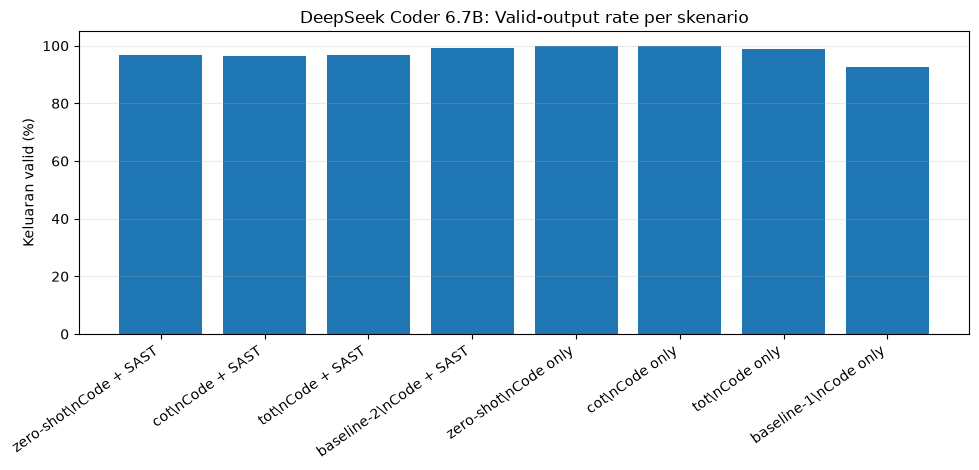

In [10]:
# Grafik deepseek: tingkat keluaran valid
plot_df = dfm.copy()
labels = plot_df["scenario_label"] + "\\n" + plot_df["sast"].replace({"Code only":"Code only","Code + FindSecBugs":"Code + SAST"})
plt.figure(figsize=(10, 4.8))
plt.bar(labels, plot_df["valid_rate_pct"])
plt.ylabel("Keluaran valid (%)")
plt.title("DeepSeek Coder 6.7B: Valid-output rate per skenario")
plt.ylim(0, 105)
plt.xticks(rotation=35, ha="right")
plt.grid(axis="y", alpha=.25)
plt.tight_layout()
plt.show()


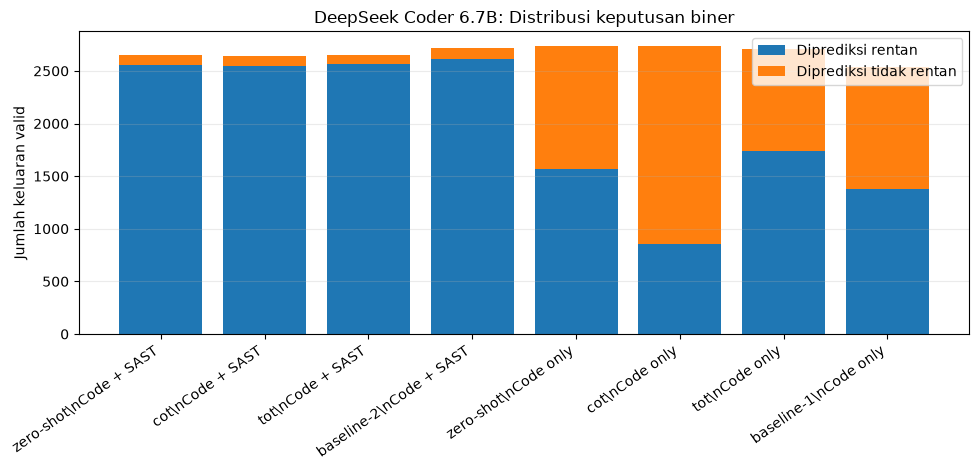

In [11]:
# Grafik deepseek: jumlah label rentan yang dikeluarkan model
plot_df = dfm.copy()
labels = plot_df["scenario_label"] + "\\n" + plot_df["sast"].replace({"Code only":"Code only","Code + FindSecBugs":"Code + SAST"})
plt.figure(figsize=(10, 4.8))
plt.bar(labels, plot_df["predicted_vulnerable"], label="Diprediksi rentan")
plt.bar(labels, plot_df["predicted_not_vulnerable"],
        bottom=plot_df["predicted_vulnerable"], label="Diprediksi tidak rentan")
plt.ylabel("Jumlah keluaran valid")
plt.title("DeepSeek Coder 6.7B: Distribusi keputusan biner")
plt.xticks(rotation=35, ha="right")
plt.legend()
plt.grid(axis="y", alpha=.25)
plt.tight_layout()
plt.show()


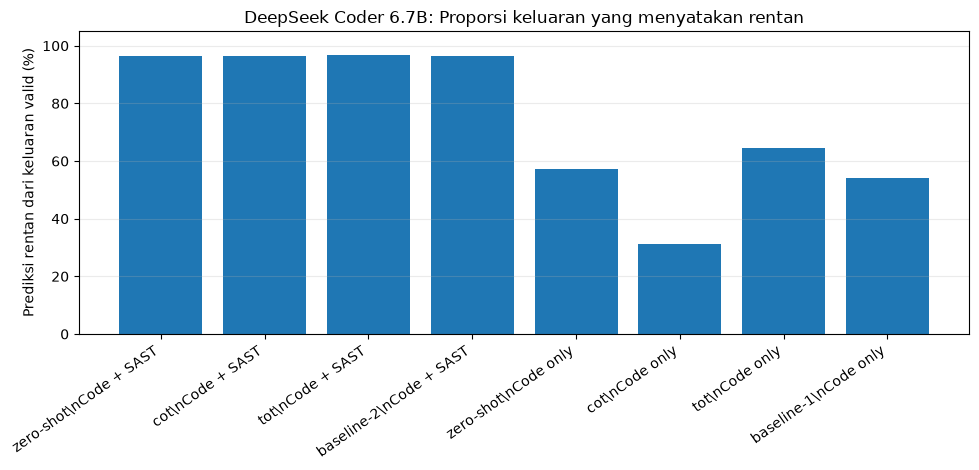

In [12]:
# Grafik deepseek: proporsi prediksi rentan di antara keluaran valid
plot_df = dfm.copy()
labels = plot_df["scenario_label"] + "\\n" + plot_df["sast"].replace({"Code only":"Code only","Code + FindSecBugs":"Code + SAST"})
plt.figure(figsize=(10, 4.8))
plt.bar(labels, plot_df["predicted_vulnerable_pct_of_valid"])
plt.ylabel("Prediksi rentan dari keluaran valid (%)")
plt.title("DeepSeek Coder 6.7B: Proporsi keluaran yang menyatakan rentan")
plt.ylim(0, 105)
plt.xticks(rotation=35, ha="right")
plt.grid(axis="y", alpha=.25)
plt.tight_layout()
plt.show()


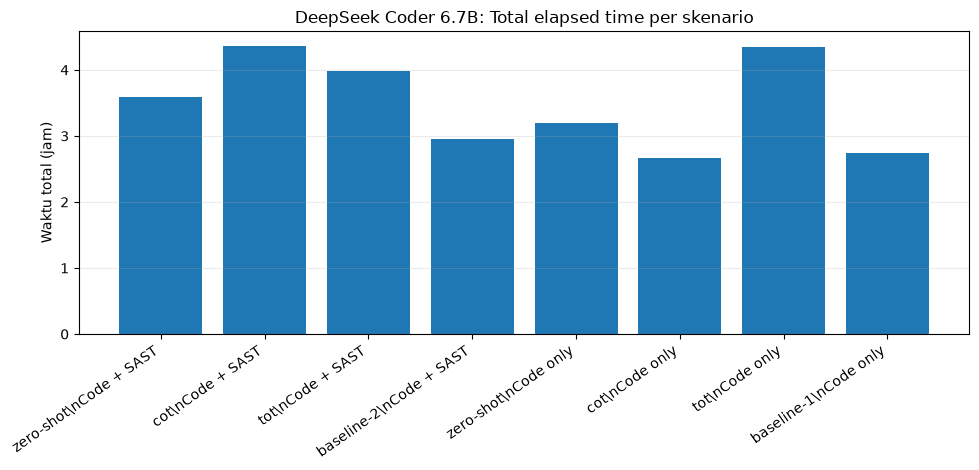

In [13]:
# Grafik deepseek: waktu inferensi
plot_df = dfm.copy()
labels = plot_df["scenario_label"] + "\\n" + plot_df["sast"].replace({"Code only":"Code only","Code + FindSecBugs":"Code + SAST"})
plt.figure(figsize=(10, 4.8))
plt.bar(labels, plot_df["elapsed_hours"])
plt.ylabel("Waktu total (jam)")
plt.title("DeepSeek Coder 6.7B: Total elapsed time per skenario")
plt.xticks(rotation=35, ha="right")
plt.grid(axis="y", alpha=.25)
plt.tight_layout()
plt.show()


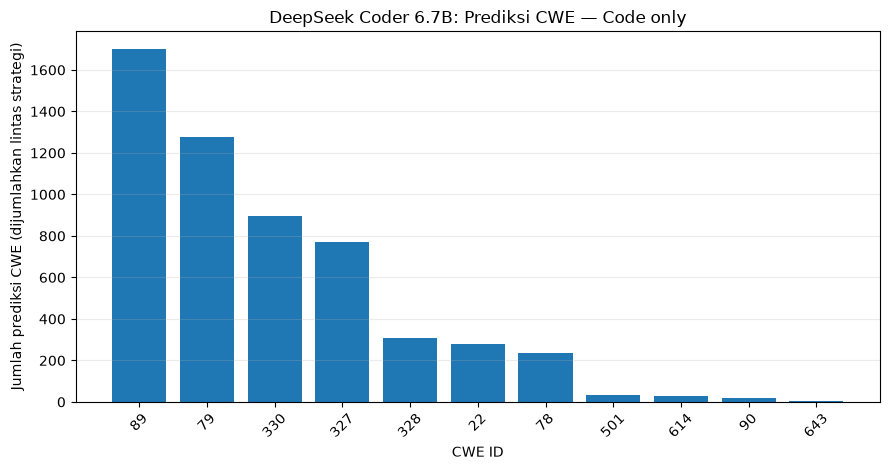

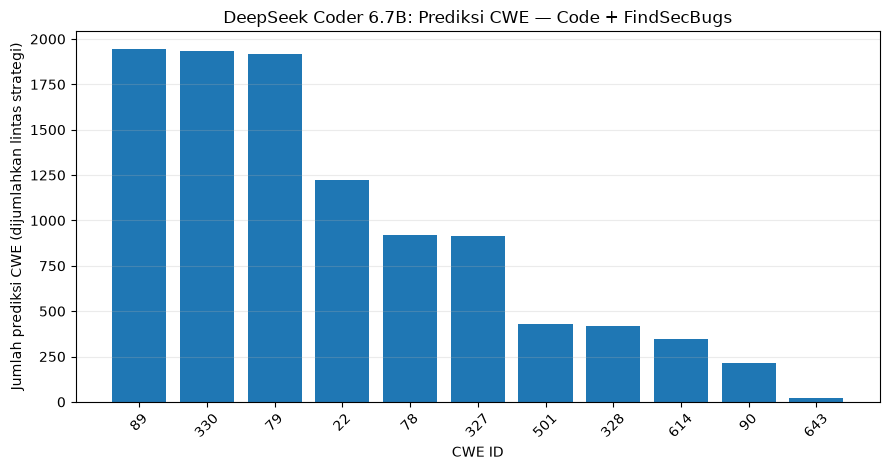

In [14]:
# Grafik deepseek: distribusi CWE yang diprediksi, satu grafik per kondisi input
for sast_condition in ["Code only", "Code + FindSecBugs"]:
    cwe_counts = {}
    for _, row in dfm[dfm["sast"] == sast_condition].iterrows():
        key = (row["model"], str(row["scenario"]), row["sast"])
        preds = predictions_by_scenario.get(key, [])
        for pred in preds:
            if pred.get("vulnerable") is True and pred.get("cwe") not in (None, ""):
                cwe = str(pred["cwe"]).replace("CWE-", "")
                cwe_counts[cwe] = cwe_counts.get(cwe, 0) + 1
    if not cwe_counts:
        print(f"Tidak ada data CWE untuk kondisi {sast_condition}")
        continue
    counts = pd.Series(cwe_counts).sort_values(ascending=False)
    plt.figure(figsize=(9, 4.8))
    plt.bar(counts.index, counts.values)
    plt.xlabel("CWE ID")
    plt.ylabel("Jumlah prediksi CWE (dijumlahkan lintas strategi)")
    plt.title(f"DeepSeek Coder 6.7B: Prediksi CWE — {sast_condition}")
    plt.xticks(rotation=45)
    plt.grid(axis="y", alpha=.25)
    plt.tight_layout()
    plt.show()


# Analisis khusus: Gemma4 E4B (thinking aktif)

Seluruh grafik pada bagian ini hanya menampilkan model ini. Perbandingan DeepSeek dan Gemma tidak digabungkan dalam satu kanvas.

In [15]:
model_name = 'Gemma4 E4B (thinking aktif)'
dfm = summary[summary["model"] == model_name].copy()
dfm["scenario_label"] = dfm["scenario"].astype("string").fillna("unknown")

display(dfm[["scenario_label","sast","predictions_valid","valid_rate_pct",
             "predicted_vulnerable","predicted_not_vulnerable",
             "predicted_vulnerable_pct_of_valid","invalid_responses",
             "elapsed_hours"]].round(2))


,scenario_label,sast,predictions_valid,valid_rate_pct,predicted_vulnerable,predicted_not_vulnerable,predicted_vulnerable_pct_of_valid,invalid_responses,elapsed_hours
8,zero-shot,Code + FindSecBugs,2599,94.85,1916,683,73.72,141,5.70
9,cot,Code + FindSecBugs,2354,85.91,1702,652,72.30,386,6.89
10,tot,Code + FindSecBugs,2212,80.73,1494,718,67.54,528,9.79
11,baseline-2,Code + FindSecBugs,2117,77.26,1465,652,69.20,623,9.45
12,zero-shot,Code only,2729,99.60,1627,1102,59.62,11,6.22
13,cot,Code only,2733,99.74,1559,1174,57.04,7,6.81
14,tot,Code only,2726,99.49,1613,1113,59.17,14,6.73
15,baseline-1,Code only,2480,90.51,1438,1042,57.98,260,7.96


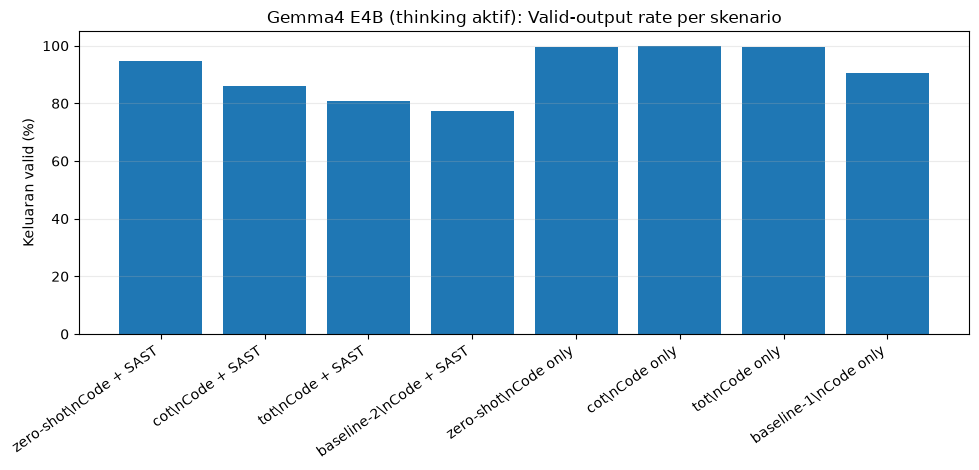

In [16]:
# Grafik gemma: tingkat keluaran valid
plot_df = dfm.copy()
labels = plot_df["scenario_label"] + "\\n" + plot_df["sast"].replace({"Code only":"Code only","Code + FindSecBugs":"Code + SAST"})
plt.figure(figsize=(10, 4.8))
plt.bar(labels, plot_df["valid_rate_pct"])
plt.ylabel("Keluaran valid (%)")
plt.title("Gemma4 E4B (thinking aktif): Valid-output rate per skenario")
plt.ylim(0, 105)
plt.xticks(rotation=35, ha="right")
plt.grid(axis="y", alpha=.25)
plt.tight_layout()
plt.show()


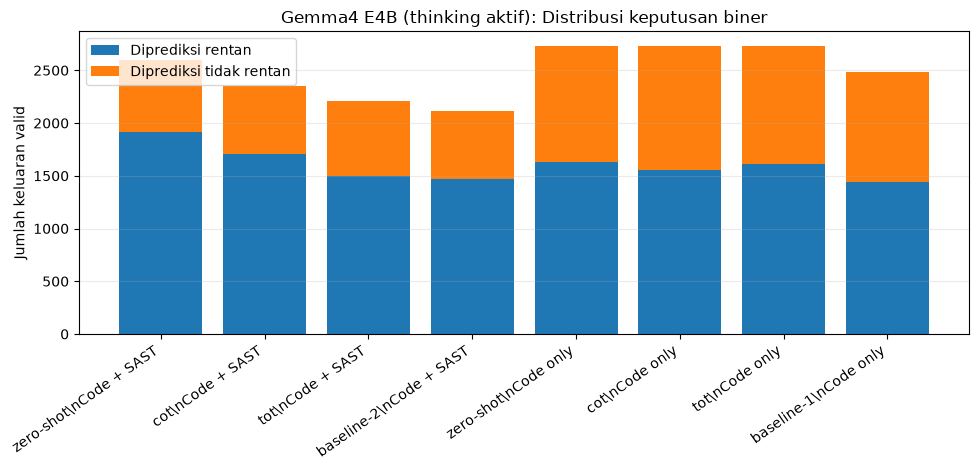

In [17]:
# Grafik gemma: jumlah label rentan yang dikeluarkan model
plot_df = dfm.copy()
labels = plot_df["scenario_label"] + "\\n" + plot_df["sast"].replace({"Code only":"Code only","Code + FindSecBugs":"Code + SAST"})
plt.figure(figsize=(10, 4.8))
plt.bar(labels, plot_df["predicted_vulnerable"], label="Diprediksi rentan")
plt.bar(labels, plot_df["predicted_not_vulnerable"],
        bottom=plot_df["predicted_vulnerable"], label="Diprediksi tidak rentan")
plt.ylabel("Jumlah keluaran valid")
plt.title("Gemma4 E4B (thinking aktif): Distribusi keputusan biner")
plt.xticks(rotation=35, ha="right")
plt.legend()
plt.grid(axis="y", alpha=.25)
plt.tight_layout()
plt.show()


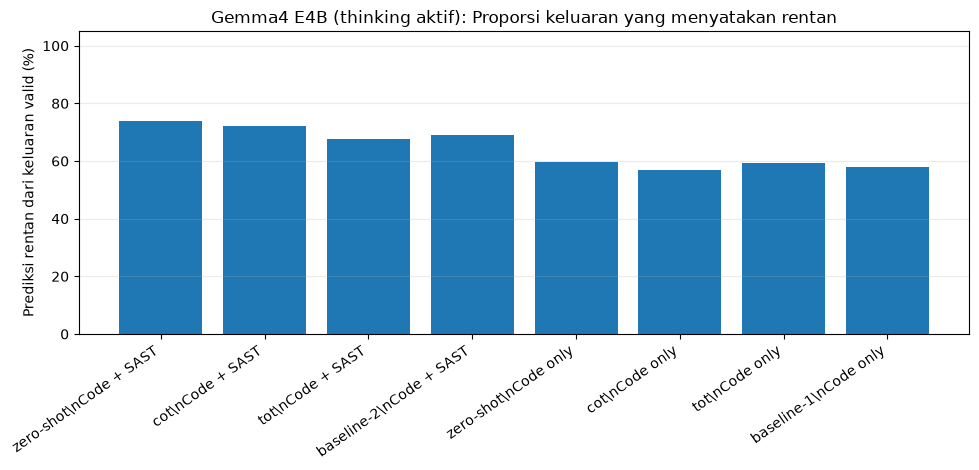

In [18]:
# Grafik gemma: proporsi prediksi rentan di antara keluaran valid
plot_df = dfm.copy()
labels = plot_df["scenario_label"] + "\\n" + plot_df["sast"].replace({"Code only":"Code only","Code + FindSecBugs":"Code + SAST"})
plt.figure(figsize=(10, 4.8))
plt.bar(labels, plot_df["predicted_vulnerable_pct_of_valid"])
plt.ylabel("Prediksi rentan dari keluaran valid (%)")
plt.title("Gemma4 E4B (thinking aktif): Proporsi keluaran yang menyatakan rentan")
plt.ylim(0, 105)
plt.xticks(rotation=35, ha="right")
plt.grid(axis="y", alpha=.25)
plt.tight_layout()
plt.show()


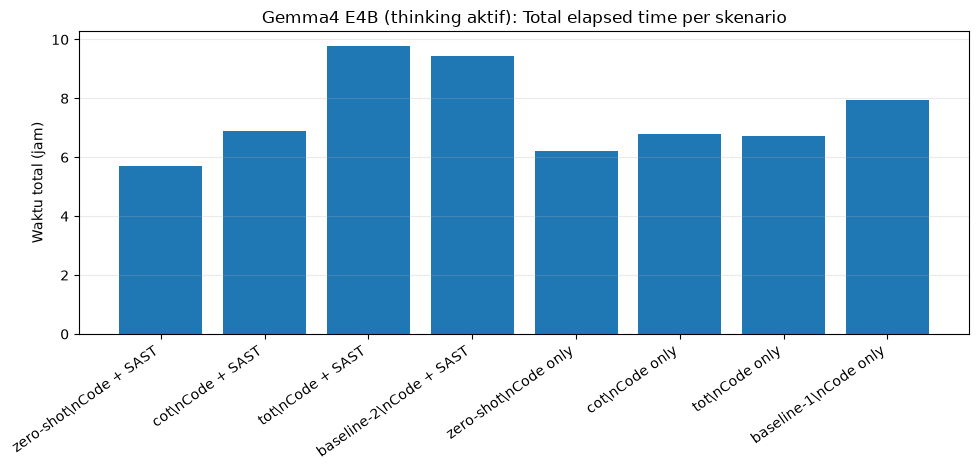

In [19]:
# Grafik gemma: waktu inferensi
plot_df = dfm.copy()
labels = plot_df["scenario_label"] + "\\n" + plot_df["sast"].replace({"Code only":"Code only","Code + FindSecBugs":"Code + SAST"})
plt.figure(figsize=(10, 4.8))
plt.bar(labels, plot_df["elapsed_hours"])
plt.ylabel("Waktu total (jam)")
plt.title("Gemma4 E4B (thinking aktif): Total elapsed time per skenario")
plt.xticks(rotation=35, ha="right")
plt.grid(axis="y", alpha=.25)
plt.tight_layout()
plt.show()


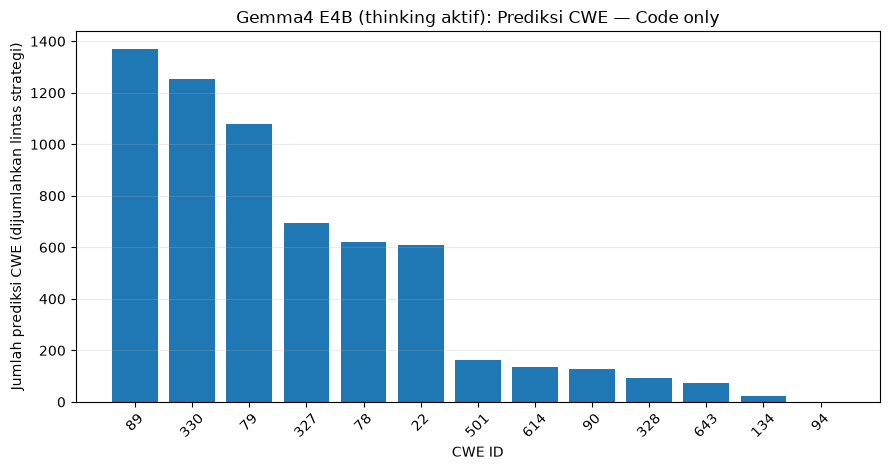

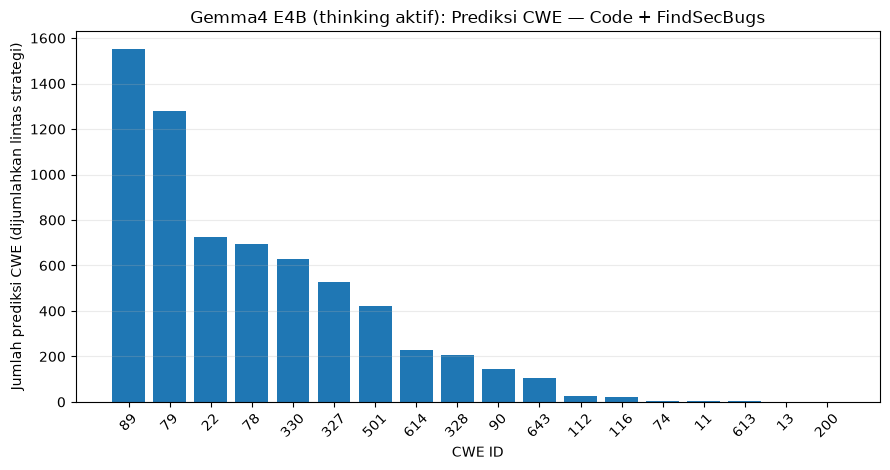

In [20]:
# Grafik gemma: distribusi CWE yang diprediksi, satu grafik per kondisi input
for sast_condition in ["Code only", "Code + FindSecBugs"]:
    cwe_counts = {}
    for _, row in dfm[dfm["sast"] == sast_condition].iterrows():
        key = (row["model"], str(row["scenario"]), row["sast"])
        preds = predictions_by_scenario.get(key, [])
        for pred in preds:
            if pred.get("vulnerable") is True and pred.get("cwe") not in (None, ""):
                cwe = str(pred["cwe"]).replace("CWE-", "")
                cwe_counts[cwe] = cwe_counts.get(cwe, 0) + 1
    if not cwe_counts:
        print(f"Tidak ada data CWE untuk kondisi {sast_condition}")
        continue
    counts = pd.Series(cwe_counts).sort_values(ascending=False)
    plt.figure(figsize=(9, 4.8))
    plt.bar(counts.index, counts.values)
    plt.xlabel("CWE ID")
    plt.ylabel("Jumlah prediksi CWE (dijumlahkan lintas strategi)")
    plt.title(f"Gemma4 E4B (thinking aktif): Prediksi CWE — {sast_condition}")
    plt.xticks(rotation=45)
    plt.grid(axis="y", alpha=.25)
    plt.tight_layout()
    plt.show()


## 4. Perbandingan prompting pada kondisi input yang sama

Bagian ini menyajikan perubahan deskriptif dari `Code only` ke `Code + FindSecBugs` untuk strategi yang sama. Selisih jumlah prediksi rentan tidak dapat langsung ditafsirkan sebagai peningkatan akurasi; perubahan itu baru dapat dinilai sebagai peningkatan atau penurunan performa setelah dibandingkan dengan ground truth.

In [21]:
paired = summary.pivot_table(
    index=["model","scenario"], columns="sast",
    values=["valid_rate_pct","predicted_vulnerable_pct_of_valid","elapsed_hours"],
    aggfunc="first", observed=False
)
display(paired.round(2))

# Selisih Code+SAST - Code only untuk setiap model dan strategi
diff_rows = []
for model in summary["model"].unique():
    for strategy in strategy_order:
        part = summary[(summary["model"] == model) & (summary["scenario"].astype(str) == strategy)]
        no_sast = part[part["sast"] == "Code only"]
        with_sast = part[part["sast"] == "Code + FindSecBugs"]
        if len(no_sast) == 1 and len(with_sast) == 1:
            a, b = no_sast.iloc[0], with_sast.iloc[0]
            diff_rows.append({
                "model": model, "scenario": strategy,
                "delta_valid_rate_pp": b["valid_rate_pct"] - a["valid_rate_pct"],
                "delta_predicted_vulnerable_pct_pp": b["predicted_vulnerable_pct_of_valid"] - a["predicted_vulnerable_pct_of_valid"],
                "delta_elapsed_hours": b["elapsed_hours"] - a["elapsed_hours"],
                "delta_invalid_responses": b["invalid_responses"] - a["invalid_responses"],
            })
display(pd.DataFrame(diff_rows).round(2))


elapsed_hours            \
sast                                   Code + FindSecBugs Code only   
model                       scenario                                  
DeepSeek Coder 6.7B         zero-shot                3.60      3.20   
                            cot                      4.37      2.67   
                            tot                      3.99      4.35   
                            baseline-1                NaN      2.74   
                            baseline-2               2.95       NaN   
Gemma4 E4B (thinking aktif) zero-shot                5.70      6.22   
                            cot                      6.89      6.81   
                            tot                      9.79      6.73   
                            baseline-1                NaN      7.96   
                            baseline-2               9.45       NaN   

                                       predicted_vulnerable_pct_of_valid  \
sast                                                  Code + FindSecBugs   
model                       scenario                                       
DeepSeek Coder 6.7B         zero-shot                              96.42   
                            cot                                    96.37   
                            tot                                    96.79   
                            baseline-1                               NaN   
                            baseline-2                             96.28   
Gemma4 E4B (thinking aktif) zero-shot                              73.72   
                            cot                                    72.30   
                            tot                                    67.54   
                            baseline-1                               NaN   
                            baseline-2                             69.20   

                                                     valid_rate_pct            
sast                                   Code only Code + FindSecBugs Code only  
model                       scenario                                           
DeepSeek Coder 6.7B         zero-shot      57.32              96.75     99.96  
                            cot            31.35              96.57     99.78  
                            tot            64.44              96.72     98.72  
                            baseline-1     54.28                NaN     92.59  
                            baseline-2       NaN              99.05       NaN  
Gemma4 E4B (thinking aktif) zero-shot      59.62              94.85     99.60  
                            cot            57.04              85.91     99.74  
                            tot            59.17              80.73     99.49  
                            baseline-1     57.98                NaN     90.51  
                            baseline-2       NaN              77.26       NaN

,model,scenario,delta_valid_rate_pp,delta_predicted_vulnerable_pct_pp,delta_elapsed_hours,delta_invalid_responses
0,DeepSeek Coder 6.7B,zero-shot,-3.21,39.10,0.40,88
1,DeepSeek Coder 6.7B,cot,-3.21,65.03,1.69,88
2,DeepSeek Coder 6.7B,tot,-2.01,32.36,-0.36,60
3,Gemma4 E4B (thinking aktif),zero-shot,-4.74,14.10,-0.52,130
4,Gemma4 E4B (thinking aktif),cot,-13.83,15.26,0.09,379
5,Gemma4 E4B (thinking aktif),tot,-18.76,8.37,3.05,514


## 5. Distribusi CWE per strategi

CWE yang muncul pada keluaran model belum tentu sesuai dengan ground truth. Notebook menghitung distribusi CWE yang **diprediksi** untuk setiap skenario, agar terlihat apakah strategi tertentu cenderung menghasilkan label tertentu atau menghasilkan label di luar kategori target.

In [22]:
cwe_rows = []
for (model, scenario, sast), preds in predictions_by_scenario.items():
    for pred in preds:
        if pred.get("vulnerable") is True and pred.get("cwe") not in (None, ""):
            cwe_rows.append({
                "model": model, "scenario": scenario, "sast": sast,
                "cwe": str(pred["cwe"]).replace("CWE-", ""),
                "test_name": pred.get("test_name")
            })
cwe_df = pd.DataFrame(cwe_rows)
if not cwe_df.empty:
    cwe_summary = (cwe_df.groupby(["model","scenario","sast","cwe"])
                   .size().rename("predicted_count").reset_index())
    display(cwe_summary.sort_values(["model","sast","scenario","predicted_count"],
                                    ascending=[True,True,True,False]))
else:
    print("Tidak ada prediksi CWE yang tersedia.")


,model,scenario,sast,cwe,predicted_count
17,DeepSeek Coder 6.7B,baseline-2,Code + FindSecBugs,79,482
18,DeepSeek Coder 6.7B,baseline-2,Code + FindSecBugs,89,482
13,DeepSeek Coder 6.7B,baseline-2,Code + FindSecBugs,330,459
10,DeepSeek Coder 6.7B,baseline-2,Code + FindSecBugs,22,270
11,DeepSeek Coder 6.7B,baseline-2,Code + FindSecBugs,327,261
...,...,...,...,...,...
185,Gemma4 E4B (thinking aktif),zero-shot,Code only,614,34
190,Gemma4 E4B (thinking aktif),zero-shot,Code only,90,34
186,Gemma4 E4B (thinking aktif),zero-shot,Code only,643,19
179,Gemma4 E4B (thinking aktif),zero-shot,Code only,134,4


## 6. Analisis per sampel dan konsistensi prediksi

Bila nama sampel tersedia pada semua skenario, bagian ini mengukur seberapa sering keputusan biner antarstrategi berbeda. Ini adalah **konsistensi antarskenario**, bukan akurasi. Perbandingan hanya menggunakan sampel yang memiliki keluaran valid pada skenario yang sedang dibandingkan.

In [23]:
sample_frames = []
for (model, scenario, sast), preds in predictions_by_scenario.items():
    for p in preds:
        if p.get("test_name") is not None and isinstance(p.get("vulnerable"), bool):
            sample_frames.append({
                "model": model, "scenario": scenario, "sast": sast,
                "test_name": p["test_name"], "pred_vulnerable": p["vulnerable"],
                "pred_cwe": str(p.get("cwe") or "")
            })
sample_df = pd.DataFrame(sample_frames)

consistency_rows = []
for model in summary["model"].unique():
    for sast in ["Code only", "Code + FindSecBugs"]:
        sub = sample_df[(sample_df["model"] == model) & (sample_df["sast"] == sast)]
        if sub.empty:
            continue
        wide = sub.pivot_table(index="test_name", columns="scenario",
                               values="pred_vulnerable", aggfunc="first")
        available_strategies = [c for c in strategy_order if c in wide.columns]
        if len(available_strategies) < 2:
            continue
        aligned = wide[available_strategies].dropna()
        if aligned.empty:
            continue
        # Untuk tiap sampel, apakah semua strategi memberi keputusan yang sama?
        all_same = aligned.nunique(axis=1) == 1
        consistency_rows.append({
            "model": model,
            "sast": sast,
            "strategies_compared": ", ".join(available_strategies),
            "samples_with_all_compared_outputs": len(aligned),
            "same_binary_decision_all_strategies": int(all_same.sum()),
            "agreement_rate_pct": 100*all_same.mean()
        })
display(pd.DataFrame(consistency_rows).round(2))


,model,sast,strategies_compared,samples_with_all_compared_outputs,same_binary_decision_all_strategies,agreement_rate_pct
0,DeepSeek Coder 6.7B,Code only,"zero-shot, cot, tot, baseline-1",2524,1100,43.58
1,DeepSeek Coder 6.7B,Code + FindSecBugs,"zero-shot, cot, tot, baseline-2",2626,2609,99.35
2,Gemma4 E4B (thinking aktif),Code only,"zero-shot, cot, tot, baseline-1",2455,1868,76.09
3,Gemma4 E4B (thinking aktif),Code + FindSecBugs,"zero-shot, cot, tot, baseline-2",1929,1465,75.95


## 7. Metrik terhadap ground truth (opsional, direkomendasikan)

Untuk menghitung metrik yang sahih, siapkan CSV ground truth dengan satu baris per sampel dan kolom:
- `test_name`: misalnya `BenchmarkTest00001`
- `true_vulnerable`: nilai boolean (`True`/`False`) atau nilai yang dapat dikonversi ke boolean
- `true_cwe`: CWE numerik, misalnya `22`, untuk sampel rentan; kosong untuk benign jika sesuai definisi dataset.

Letakkan file bernama `ground_truth.csv` di folder notebook. Jika file tidak tersedia, sel berikut berhenti dengan pesan penjelasan. **Pastikan ground truth berasal dari label dataset asli, bukan hasil prediksi model atau inferensi dari nama sampel.**

In [24]:
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, matthews_corrcoef
)

gt_path = DATA_DIR / "ground_truth.csv"
if not gt_path.exists():
    print("ground_truth.csv tidak ditemukan. Metrik accuracy/precision/recall/F1/FPR/MCC tidak dihitung.")
    print("File ground truth diletakkan otomatis di results/llm/raw/ground_truth.csv jika tersedia.")
else:
    # Repository ground_truth.csv uses a descriptive comment as its first line, followed by data.
    gt_raw = pd.read_csv(gt_path, header=None, skiprows=1, usecols=range(4),
                         names=["test_name", "category", "true_vulnerable", "true_cwe"])

    def as_bool(x):
        if isinstance(x, bool): return x
        if pd.isna(x): return np.nan
        s = str(x).strip().lower()
        if s in {"true", "1", "yes", "vulnerable", "v"}: return True
        if s in {"false", "0", "no", "benign", "not vulnerable", "n"}: return False
        return np.nan

    gt = gt_raw.copy()
    gt["test_name"] = gt["test_name"].astype("string").str.strip()
    gt["true_vulnerable_bool"] = gt["true_vulnerable"].map(as_bool)
    gt["true_cwe_norm"] = gt["true_cwe"].astype("string").str.replace("CWE-", "", regex=False).str.strip()
    metric_rows, cwe_metric_rows = [], []
    for (model, scenario, sast), preds in predictions_by_scenario.items():
        pred_df = pd.DataFrame(preds)
        if pred_df.empty or not {"test_name", "vulnerable"}.issubset(pred_df.columns):
            continue
        pred_df = pred_df.rename(columns={"vulnerable":"pred_vulnerable", "cwe":"pred_cwe"})
        pred_df["test_name"] = pred_df["test_name"].astype("string").str.strip()
        pred_df["pred_vulnerable"] = pred_df["pred_vulnerable"].map(as_bool)
        merged = gt.merge(pred_df[["test_name", "pred_vulnerable", "pred_cwe"]], on="test_name", how="inner")
        merged = merged.dropna(subset=["true_vulnerable_bool", "pred_vulnerable"])
        if merged.empty:
            continue
        y_true = merged["true_vulnerable_bool"].astype(bool)
        y_pred = merged["pred_vulnerable"].astype(bool)
        tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[False, True]).ravel()
        metric_rows.append({
            "model": model, "scenario": scenario, "sast": sast,
            "n_evaluated": len(merged), "TP": int(tp), "FP": int(fp), "TN": int(tn), "FN": int(fn),
            "accuracy": accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred, zero_division=0),
            "recall": recall_score(y_true, y_pred, zero_division=0),
            "f1": f1_score(y_true, y_pred, zero_division=0),
            "FPR": fp/(fp+tn) if (fp+tn) else np.nan,
            "specificity": tn/(tn+fp) if (tn+fp) else np.nan,
            "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
            "MCC": matthews_corrcoef(y_true, y_pred),
        })
        vulnerable_pairs = merged[(merged["true_vulnerable_bool"] == True) & (merged["pred_vulnerable"] == True)].copy()
        if not vulnerable_pairs.empty:
            true_cwe = vulnerable_pairs["true_cwe_norm"].fillna("").astype(str).str.strip()
            pred_cwe = vulnerable_pairs["pred_cwe"].fillna("").astype(str).str.replace("CWE-", "", regex=False).str.strip()
            cwe_metric_rows.append({
                "model": model, "scenario": scenario, "sast": sast,
                "n_true_vuln_and_pred_vuln": len(vulnerable_pairs),
                "CWE_exact_match_rate": (true_cwe == pred_cwe).mean(),
            })

    metrics_df = pd.DataFrame(metric_rows)
    cwe_metrics_df = pd.DataFrame(cwe_metric_rows)
    if metrics_df.empty:
        print("Ground truth ditemukan, tetapi tidak ada pasangan sampel yang cocok dengan prediksi.")
    else:
        display(metrics_df.round(4))
        display(cwe_metrics_df.round(4))


,model,scenario,sast,n_evaluated,TP,FP,TN,FN,accuracy,precision,recall,f1,FPR,specificity,balanced_accuracy,MCC
0,DeepSeek Coder 6.7B,baseline-1,Code only,2537,775,602,632,528,0.5546,0.5628,0.5948,0.5784,0.4878,0.5122,0.5535,0.1073
1,DeepSeek Coder 6.7B,baseline-2,Code + FindSecBugs,2714,1399,1214,96,5,0.5508,0.5354,0.9964,0.6965,0.9267,0.0733,0.5349,0.1841
2,DeepSeek Coder 6.7B,cot,Code + FindSecBugs,2646,1328,1222,94,2,0.5374,0.5208,0.9985,0.6845,0.9286,0.0714,0.5350,0.1870
3,DeepSeek Coder 6.7B,cot,Code only,2734,463,394,930,947,0.5095,0.5403,0.3284,0.4085,0.2976,0.7024,0.5154,0.0332
4,DeepSeek Coder 6.7B,tot,Code + FindSecBugs,2650,1329,1236,83,2,0.5328,0.5181,0.9985,0.6822,0.9371,0.0629,0.5307,0.1743
5,DeepSeek Coder 6.7B,tot,Code only,2705,903,840,475,487,0.5094,0.5181,0.6496,0.5764,0.6388,0.3612,0.5054,0.0113
6,DeepSeek Coder 6.7B,zero-shot,Code + FindSecBugs,2651,1331,1225,93,2,0.5372,0.5207,0.9985,0.6845,0.9294,0.0706,0.5345,0.1858
7,DeepSeek Coder 6.7B,zero-shot,Code only,2739,810,760,564,605,0.5016,0.5159,0.5724,0.5427,0.5740,0.4260,0.4992,-0.0016
8,Gemma4 E4B (thinking aktif),baseline-1,Code only,2480,1132,306,931,111,0.8319,0.7872,0.9107,0.8445,0.2474,0.7526,0.8317,0.6719
9,Gemma4 E4B (thinking aktif),baseline-2,Code + FindSecBugs,2117,1091,374,615,37,0.8059,0.7447,0.9672,0.8415,0.3782,0.6218,0.7945,0.6366


,model,scenario,sast,n_true_vuln_and_pred_vuln,CWE_exact_match_rate
0,DeepSeek Coder 6.7B,baseline-1,Code only,775,0.9484
1,DeepSeek Coder 6.7B,baseline-2,Code + FindSecBugs,1399,0.9707
2,DeepSeek Coder 6.7B,cot,Code + FindSecBugs,1328,0.9556
3,DeepSeek Coder 6.7B,cot,Code only,463,0.8747
4,DeepSeek Coder 6.7B,tot,Code + FindSecBugs,1329,0.9639
5,DeepSeek Coder 6.7B,tot,Code only,903,0.8472
6,DeepSeek Coder 6.7B,zero-shot,Code + FindSecBugs,1331,0.9609
7,DeepSeek Coder 6.7B,zero-shot,Code only,810,0.8444
8,Gemma4 E4B (thinking aktif),baseline-1,Code only,1132,0.9470
9,Gemma4 E4B (thinking aktif),baseline-2,Code + FindSecBugs,1091,0.9496


## 8. Ringkasan interpretasi yang dapat dipertanggungjawabkan

Gunakan panduan ini saat menulis hasil:
- `valid_rate_pct` mengukur keberhasilan keluaran memenuhi parser/format yang diharapkan, bukan keberhasilan deteksi kerentanan.
- `predicted_vulnerable` dan `predicted_vulnerable_pct_of_valid` mengukur kecenderungan model memberi label rentan, bukan true positive rate.
- `elapsed_hours` adalah waktu total pada metadata skenario; jangan menyimpulkan throughput per sampel tanpa memeriksa apakah waktu mencakup retry, antrean, dan pemrosesan lainnya.
- Distribusi CWE adalah label yang diprediksi. Akurasi CWE perlu dibandingkan dengan CWE ground truth.
- Hasil Gemma4 E4B dengan thinking aktif merupakan kondisi eksperimen berbeda dari DeepSeek Coder 6.7B dengan thinking nonaktif. Karena model dan pengaturan berpikir berbeda, perbedaan hasil tidak boleh diatribusikan hanya kepada strategi prompting.
- Untuk klaim utama tentang dampak prompting, bandingkan strategi di dalam model yang sama dan kondisi input yang sama. Analisis pengaruh SAST dengan membandingkan Code only vs Code + FindSecBugs pada model dan strategi yang sama.
- Jika ingin menyimpulkan peningkatan/penurunan performa, gunakan metrik ground-truth dan laporkan jumlah sampel yang benar-benar dievaluasi pada setiap skenario.

In [25]:
# Ringkasan otomatis per model (deskriptif; tidak mengklaim akurasi)
for model_name, group in summary.groupby("model"):
    print("\n" + "="*80)
    print(model_name)
    print("="*80)
    best_valid = group.loc[group["valid_rate_pct"].idxmax()]
    fastest = group.loc[group["elapsed_seconds"].idxmin()]
    most_vuln = group.loc[group["predicted_vulnerable_pct_of_valid"].idxmax()]
    print(f"Tingkat keluaran valid tertinggi: {best_valid['scenario']} | {best_valid['sast']} "
          f"({best_valid['valid_rate_pct']:.2f}%)")
    print(f"Waktu total terendah: {fastest['scenario']} | {fastest['sast']} "
          f"({fastest['elapsed_hours']:.2f} jam)")
    print(f"Proporsi prediksi rentan tertinggi: {most_vuln['scenario']} | {most_vuln['sast']} "
          f"({most_vuln['predicted_vulnerable_pct_of_valid']:.2f}%)")
    print("Catatan: ketiganya indikator deskriptif, bukan penilaian akurasi.")



DeepSeek Coder 6.7B
Tingkat keluaran valid tertinggi: zero-shot | Code only (99.96%)
Waktu total terendah: cot | Code only (2.67 jam)
Proporsi prediksi rentan tertinggi: tot | Code + FindSecBugs (96.79%)
Catatan: ketiganya indikator deskriptif, bukan penilaian akurasi.

Gemma4 E4B (thinking aktif)
Tingkat keluaran valid tertinggi: cot | Code only (99.74%)
Waktu total terendah: zero-shot | Code + FindSecBugs (5.70 jam)
Proporsi prediksi rentan tertinggi: zero-shot | Code + FindSecBugs (73.72%)
Catatan: ketiganya indikator deskriptif, bukan penilaian akurasi.
